# Support Vector Machines - Exercise 1

In this exercise, we'll be using support vector machines (SVMs) to build a spam classifier.  We'll start with SVMs on some simple 2D data sets to see how they work.  Then we'll do some pre-processing work on a set of raw emails and build a classifier on the processed emails using a SVM to determine if they are spam or not.

The first thing we're going to do is look at a simple 2-dimensional data set and see how a linear SVM works on the data set for varying values of C (similar to the regularization term in linear/logistic regression).  Let's load the data.
## Exercise 1
#### 1. Load libraries

In [183]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#### 2. Load data
Load the file *ejer_1_data1.mat*. Find the way for loading this kind of file. **scipy.io.loadmat**

In [184]:
import scipy.io as sio

mat = sio.loadmat('data/ejer_1_data1.mat')
mat

{'__header__': b'MATLAB 5.0 MAT-file, Platform: GLNXA64, Created on: Sun Nov 13 14:28:43 2011',
 '__version__': '1.0',
 '__globals__': [],
 'X': array([[1.9643  , 4.5957  ],
        [2.2753  , 3.8589  ],
        [2.9781  , 4.5651  ],
        [2.932   , 3.5519  ],
        [3.5772  , 2.856   ],
        [4.015   , 3.1937  ],
        [3.3814  , 3.4291  ],
        [3.9113  , 4.1761  ],
        [2.7822  , 4.0431  ],
        [2.5518  , 4.6162  ],
        [3.3698  , 3.9101  ],
        [3.1048  , 3.0709  ],
        [1.9182  , 4.0534  ],
        [2.2638  , 4.3706  ],
        [2.6555  , 3.5008  ],
        [3.1855  , 4.2888  ],
        [3.6579  , 3.8692  ],
        [3.9113  , 3.4291  ],
        [3.6002  , 3.1221  ],
        [3.0357  , 3.3165  ],
        [1.5841  , 3.3575  ],
        [2.0103  , 3.2039  ],
        [1.9527  , 2.7843  ],
        [2.2753  , 2.7127  ],
        [2.3099  , 2.9584  ],
        [2.8283  , 2.6309  ],
        [3.0473  , 2.2931  ],
        [2.4827  , 2.0373  ],
        [2.5057 

In [185]:
mat.keys()

dict_keys(['__header__', '__version__', '__globals__', 'X', 'y'])

In [186]:
mat['y']

array([[1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [1]], dtype=uint8)

#### 3. Create a DataFrame with the features and target

In [187]:
df = pd.DataFrame(mat['X'], columns=['x1','x2'])
df['y'] = mat['y']
df.head()

,x1,x2,y
0,1.9643,4.5957,1
1,2.2753,3.8589,1
2,2.9781,4.5651,1
3,2.9320,3.5519,1
4,3.5772,2.8560,1


In [188]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 51 entries, 0 to 50
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x1      51 non-null     float64
 1   x2      51 non-null     float64
 2   y       51 non-null     uint8  
dtypes: float64(2), uint8(1)
memory usage: 999.0 bytes


In [189]:
df.describe()

,x1,x2,y
count,51.000000,51.000000,51.000000
mean,2.268780,3.132512,0.411765
std,0.928531,0.753256,0.497050
min,0.086405,1.617700,0.000000
25%,1.572550,2.636000,0.000000
50%,2.275300,3.070900,0.000000
75%,2.955050,3.531400,1.000000
max,4.015000,4.616200,1.000000


In [190]:
df['y'].value_counts(normalize=True)

y
0    0.588235
1    0.411765
Name: proportion, dtype: float64

#### 4. Plot a scatterplot with the data

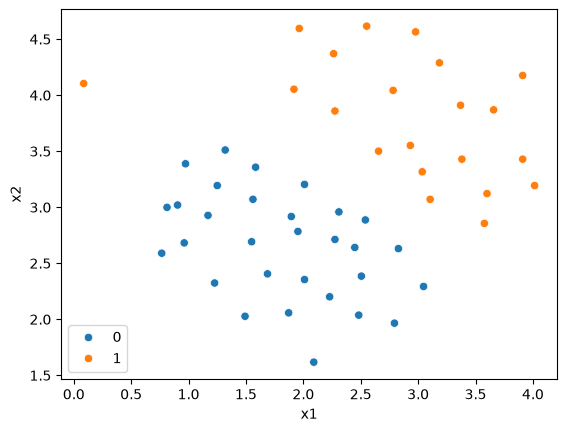

In [191]:
sns.scatterplot(df, x='x1', y='x2', hue="y")
plt.legend(loc="lower left")

Notice that there is one outlier positive example that sits apart from the others.  The classes are still linearly separable but it's a very tight fit.  We're going to train a linear support vector machine to learn the class boundary.

#### 5. LinearSVC
Declare a Linear SVC with the hyperparamenters:

```Python
LinearSVC(C=1, loss='hinge', max_iter=10000)
```

In [192]:
from sklearn.svm import LinearSVC

svc_1 = LinearSVC(C=1, loss='hinge', max_iter=10000)

#### 6. Try the performance (score)
For the first experiment we'll use C=1 and see how it performs.

In [193]:
X = df[['x1', 'x2']]
y = df['y']

svc_1.fit(X, y)
svc_1.score(X, y)

0.9803921568627451

It appears that it mis-classified the outlier.

#### 7. Increase the value of C until you get a perfect classifier

In [194]:
svc_2 = LinearSVC(C=1000, loss='hinge', max_iter=1000000)

X = df[['x1', 'x2']]
y = df['y']

svc_2.fit(X, y)
svc_2.score(X, y)

1.0

This time we got a perfect classification of the training data, however by increasing the value of C we've created a decision boundary that is no longer a natural fit for the data.  We can visualize this by looking at the confidence level for each class prediction, which is a function of the point's distance from the hyperplane.

#### 8. Plot Decission Function
Get the `decision_function()` output for the first model. Plot a scatterplot with X1, X2 and a range of colors based on `decision_function()`

In [195]:
conf_level = svc_1.decision_function(X)
conf_level

array([ 0.80285259,  0.38392957,  1.37751577,  0.52118817,  0.33342405,
        0.86872493,  0.68654369,  1.61123774,  0.83450337,  1.16715578,
        1.07326331,  0.22982457,  0.33184206,  0.79582882,  0.31581483,
        1.27411655,  1.21021889,  1.        ,  0.56476754,  0.3899131 ,
       -0.43521582, -0.30878629, -0.68619942, -0.55395625, -0.33244334,
       -0.2937688 , -0.44062895, -0.98392171, -0.68556299, -1.32842274,
       -1.0037317 , -1.49226352, -0.61136208, -0.68339273, -0.9999874 ,
       -1.15268998, -1.57836437, -1.35594438, -1.03235458, -1.18500584,
       -0.77137064, -0.76687931, -0.46645297, -0.99992812, -0.5102664 ,
       -0.85856305, -1.55896788, -0.25482185, -1.11360989, -1.54715865,
       -0.70992248])

<Axes: xlabel='x1', ylabel='x2'>

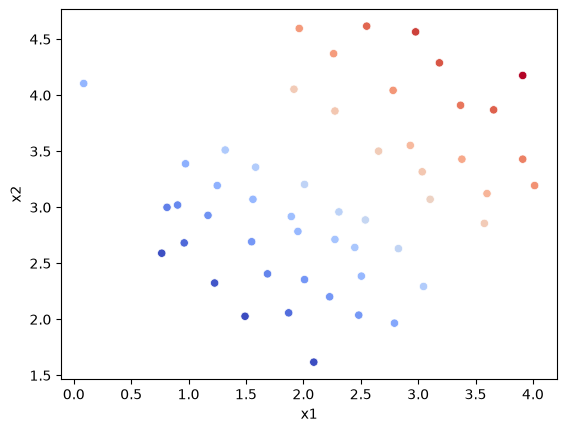

In [196]:
sns.scatterplot(df, x='x1', y='x2', c=conf_level, cmap="coolwarm")

#### 9. Do the same with the second model

https://www.svm-tutorial.com/2015/06/svm-understanding-math-part-3/

In [197]:
conf_level = svc_2.decision_function(X)
conf_level

array([ 12.00373072,   6.08410789,  15.14530757,   5.4015894 ,
         1.00007205,   5.67735998,   5.76052332,  14.62263626,
         9.54272233,  14.18607222,  10.27286446,   1.43481886,
         6.71603896,  10.88729503,   3.98224527,  13.23267091,
        10.86089161,   7.55393435,   3.59596164,   3.52501503,
        -0.99985359,  -1.01089235,  -5.17642112,  -4.7621386 ,
        -2.32003044,  -3.66460315,  -6.11994179, -10.45137356,
        -7.08048172, -12.32486747,  -9.04763737, -11.98950971,
        -4.1118675 ,  -3.79006875,  -7.41160089,  -9.65556858,
       -13.90119016,  -9.49742197,  -6.47176852,  -7.00281398,
        -2.77682707,  -3.68059715,  -0.44513679,  -9.76026908,
        -4.85450569, -10.07695829, -15.74764138,  -2.21873892,
        -6.49583585, -11.03178585,   1.        ])

<Axes: xlabel='x1', ylabel='x2'>

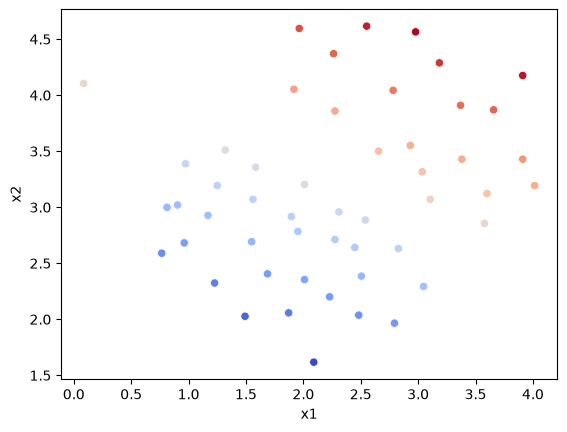

In [198]:
sns.scatterplot(df, x='x1', y='x2', c=conf_level, cmap="coolwarm")

y = ax1 + bx2 + c

0 = ax1 + bx2 + c

x2 = -ax1/b - c/b

In [199]:
svc_2.coef_

array([[3.38443296, 9.46278702]])

In [200]:
svc_2.intercept_

array([-38.13244127])

In [201]:
a = svc_2.coef_[0][0]
b = svc_2.coef_[0][1]
c = svc_2.intercept_

In [202]:
x_points = df['x1'].sort_values()
y_points = -a/b * x_points - c/b

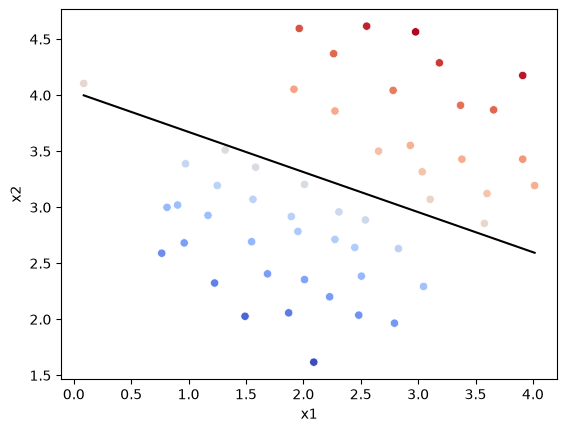

In [203]:
conf_level = svc_2.decision_function(X)
sns.scatterplot(df, x='x1', y='x2', c=conf_level, cmap="coolwarm")
plt.plot(x_points, y_points, color="black")

In [204]:
a = svc_1.coef_[0][0]
b = svc_1.coef_[0][1]
c = svc_1.intercept_
x_points = df['x1'].sort_values()
y_points = -a/b * x_points - c/b

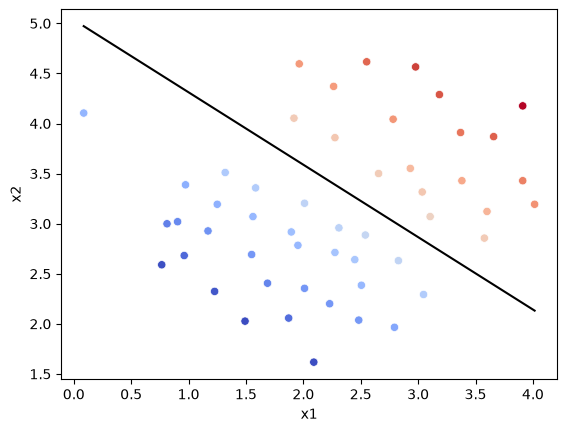

In [205]:
conf_level = svc_1.decision_function(X)
sns.scatterplot(df, x='x1', y='x2', c=conf_level, cmap="coolwarm")
plt.plot(x_points, y_points, color="black")

Now we're going to move from a linear SVM to one that's capable of non-linear classification using kernels.  We're first tasked with implementing a gaussian kernel function.  Although scikit-learn has a gaussian kernel built in, for transparency we'll implement one from scratch.

## Exercise 2

That result matches the expected value from the exercise.  Next we're going to examine another data set, this time with a non-linear decision boundary.

#### 1. Load the data `ejer_1_data2.mat`

In [206]:
mat = sio.loadmat('data/ejer_1_data2.mat')
mat.keys()

dict_keys(['__header__', '__version__', '__globals__', 'X', 'y'])

#### 2. Create a DataFrame with the features and target

In [207]:
df = pd.DataFrame(mat['X'], columns=['x1','x2'])
df['y'] = mat['y']
df.head()

,x1,x2,y
0,0.107143,0.603070,1
1,0.093318,0.649854,1
2,0.097926,0.705409,1
3,0.155530,0.784357,1
4,0.210829,0.866228,1


In [208]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 863 entries, 0 to 862
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x1      863 non-null    float64
 1   x2      863 non-null    float64
 2   y       863 non-null    uint8  
dtypes: float64(2), uint8(1)
memory usage: 14.5 KB


In [209]:
df.describe()

,x1,x2,y
count,863.000000,863.000000,863.000000
mean,0.503414,0.694304,0.556199
std,0.254967,0.158884,0.497120
min,0.044931,0.402632,0.000000
25%,0.292627,0.557018,0.000000
50%,0.512673,0.693713,1.000000
75%,0.699309,0.830409,1.000000
max,0.998848,0.988596,1.000000


#### 3. Plot a scatterplot with the data

<Axes: xlabel='x1', ylabel='x2'>

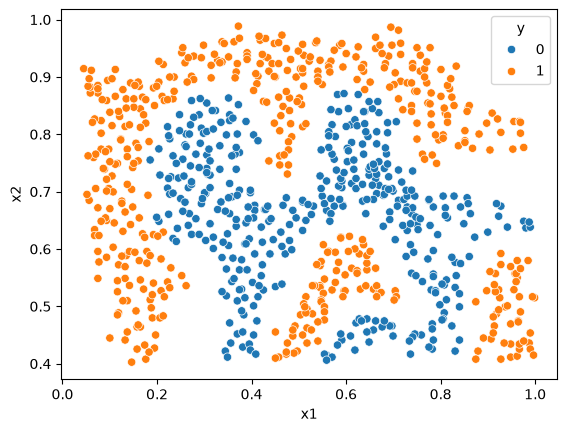

In [210]:
sns.scatterplot(df, x='x1', y='x2', hue="y")

For this data set we'll build a support vector machine classifier using the built-in RBF kernel and examine its accuracy on the training data.  To visualize the decision boundary, this time we'll shade the points based on the predicted probability that the instance has a negative class label.  We'll see from the result that it gets most of them right.

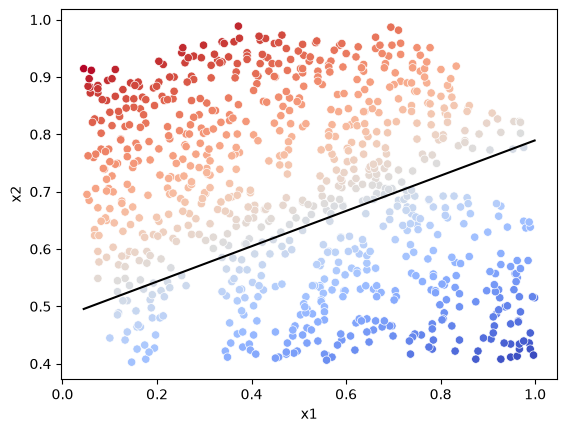

In [211]:
svc_3 = LinearSVC(C=1, loss="hinge", max_iter=10000)

X = df[['x1','x2']]
y = df['y']

svc_3.fit(X, y)
svc_3.score(X, y)

a = svc_3.coef_[0][0]
b = svc_3.coef_[0][1]
c = svc_3.intercept_
x_points = df['x1'].sort_values()
y_points = -a/b * x_points - c/b
conf_level = svc_3.decision_function(X)
sns.scatterplot(df, x='x1', y='x2', c=conf_level, cmap="coolwarm")
plt.plot(x_points, y_points, color="black")

#### 4. Declare a SVC with this hyperparameters
```Python
SVC(C=100, gamma=10, probability=True)
```


In [212]:
from sklearn.svm import SVC

In [213]:
svc_4 = SVC(C=100, gamma=10, probability=True)

#### 5. Fit the classifier and get the score

In [214]:
svc_4.fit(X, y)
svc_4.score(X, y)

c:\ProgramData\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


0.9698725376593279

#### 6. Plot the scatter plot and probability of predicting 0 with a [sequential color](https://matplotlib.org/3.1.1/tutorials/colors/colormaps.html)

In [215]:
y_pred_proba = svc_4.predict_proba(X)
y_pred_proba

array([[3.0000009e-14, 1.0000000e+00],
       [3.0000009e-14, 1.0000000e+00],
       [3.0000009e-14, 1.0000000e+00],
       ...,
       [3.0000009e-14, 1.0000000e+00],
       [3.0000009e-14, 1.0000000e+00],
       [3.0000009e-14, 1.0000000e+00]], shape=(863, 2))

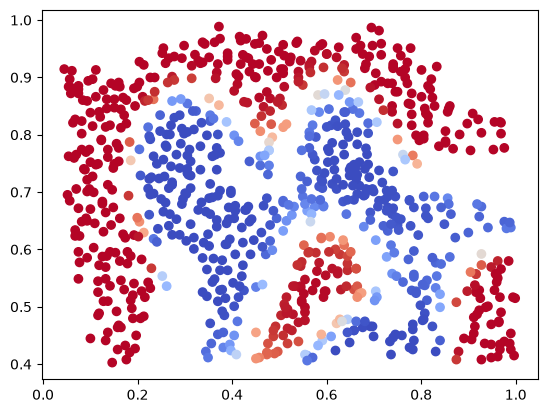

In [216]:
plt.scatter(df['x1'], df['x2'], c=y_pred_proba[:,1], cmap="coolwarm")

c:\ProgramData\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


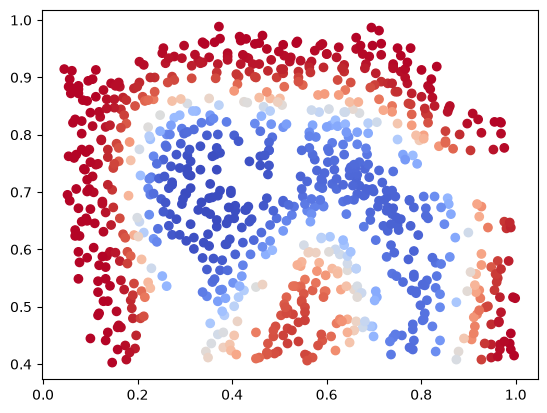

In [217]:
svc_5 = SVC(C=1, gamma=10, probability=True)
svc_5.fit(X, y)
svc_5.score(X, y)
y_pred_proba = svc_5.predict_proba(X)
plt.scatter(df['x1'], df['x2'], c=y_pred_proba[:,1], cmap="coolwarm")

c:\ProgramData\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


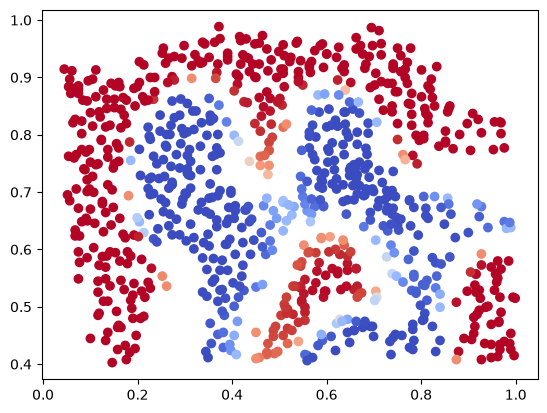

In [218]:
svc_6 = SVC(C=10000, gamma=10, probability=True)
svc_6.fit(X, y)
svc_6.score(X, y)
y_pred_proba = svc_6.predict_proba(X)
plt.scatter(df['x1'], df['x2'], c=y_pred_proba[:,1], cmap="coolwarm")

In [219]:
from sklearn.model_selection import train_test_split, GridSearchCV

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

<Axes: xlabel='x1', ylabel='x2'>

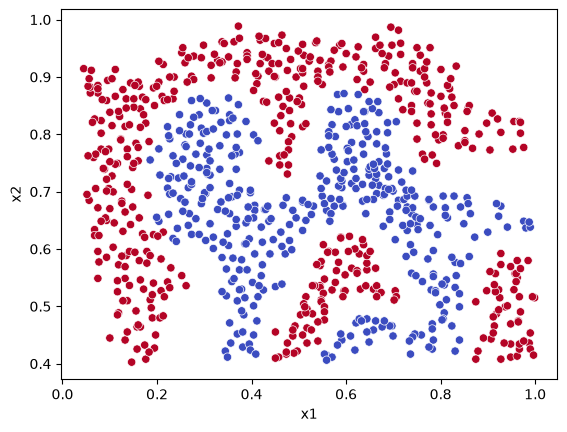

In [220]:
sns.scatterplot(df, x='x1', y='x2', c=df['y'], cmap="coolwarm")

<Axes: xlabel='x1', ylabel='x2'>

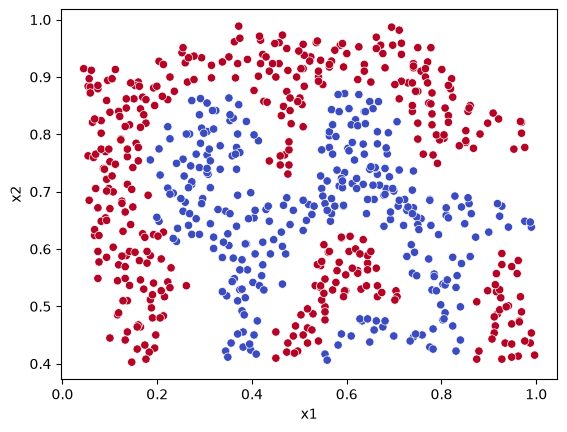

In [221]:
sns.scatterplot(X_train, x='x1', y='x2', c=y_train, cmap="coolwarm")

<Axes: xlabel='x1', ylabel='x2'>

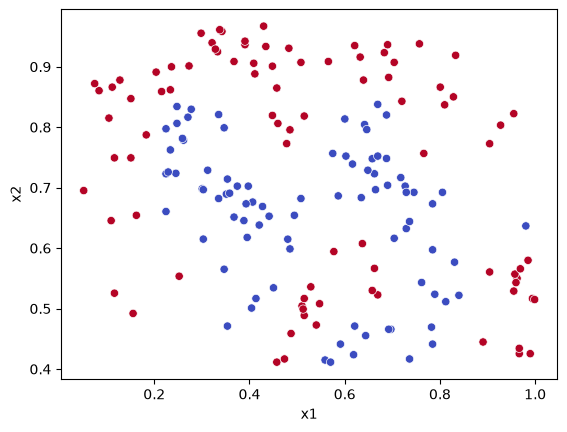

In [222]:
sns.scatterplot(X_test, x='x1', y='x2', c=y_test, cmap="coolwarm")

In [223]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV

parameters = {
    "estimator__kernel": ["rbf", "poly"],
    "estimator__C": [1, 10, 50, 100]
}

gs = GridSearchCV(
    CalibratedClassifierCV(
        estimator=SVC(),
        ensemble=False
    ),
    parameters,
    cv=5,
    scoring="accuracy",
    verbose=2
)

gs.fit(X_train, y_train)

print(gs.best_estimator_)
print(gs.best_params_)
print(gs.best_score_)

Fitting 5 folds for each of 8 candidates, totalling 40 fits
[CV] END ..............estimator__C=1, estimator__kernel=rbf; total time=   0.2s
[CV] END ..............estimator__C=1, estimator__kernel=rbf; total time=   0.1s
[CV] END ..............estimator__C=1, estimator__kernel=rbf; total time=   0.1s
[CV] END ..............estimator__C=1, estimator__kernel=rbf; total time=   0.1s
[CV] END ..............estimator__C=1, estimator__kernel=rbf; total time=   0.1s
[CV] END .............estimator__C=1, estimator__kernel=poly; total time=   0.7s
[CV] END .............estimator__C=1, estimator__kernel=poly; total time=   0.6s
[CV] END .............estimator__C=1, estimator__kernel=poly; total time=   0.7s
[CV] END .............estimator__C=1, estimator__kernel=poly; total time=   0.6s
[CV] END .............estimator__C=1, estimator__kernel=poly; total time=   0.8s
[CV] END .............estimator__C=10, estimator__kernel=rbf; total time=   0.1s
[CV] END .............estimator__C=10, estimator_

In [224]:
final_model = gs.best_estimator_
final_model.fit(X_train, y_train)
final_model.score(X_test, y_test)

0.9364161849710982

In [225]:
import pickle

filename = "final_model.pkl"

with open(filename, "wb") as archivo_salida:
    pickle.dump(final_model, archivo_salida)

In [226]:
with open(filename, 'rb') as archivo_entrada:
    modelo_importado = pickle.load(archivo_entrada)

In [227]:
modelo_importado

,"estimator estimator: estimator instance, default=NoneThe classifier whose output need to be calibrated to provide moreaccurate `predict_proba` outputs. The default classifier isa :class:`~sklearn.svm.LinearSVC`... versionadded:: 1.2",SVC(C=100)
,"ensemble ensemble: bool, or ""auto"", default=""auto""Determines how the calibrator is fitted.""auto"" will use `False` if the `estimator` is a:class:`~sklearn.frozen.FrozenEstimator`, and `True` otherwise.If `True`, the `estimator` is fitted using training data, andcalibrated using testing data, for each `cv` fold. The final estimatoris an ensemble of `n_cv` fitted classifier and calibrator pairs, where`n_cv` is the number of cross-validation folds. The output is theaverage predicted probabilities of all pairs.If `False`, `cv` is used to compute unbiased predictions, via:func:`~sklearn.model_selection.cross_val_predict`, which are thenused for calibration. At prediction time, the classifier used is the`estimator` trained on all the data.Note that this method is also internally implemented in:mod:`sklearn.svm` estimators with the `probabilities=True` parameter... versionadded:: 0.24.. versionchanged:: 1.6 `""auto""` option is added and is the default.",False
,"method method: {'sigmoid', 'isotonic', 'temperature'}, default='sigmoid'The method to use for calibration. Can be:- 'sigmoid', which corresponds to Platt's method (i.e. a binary logistic regression model).- 'isotonic', which is a non-parametric approach.- 'temperature', temperature scaling.Sigmoid and isotonic calibration methods natively support only binaryclassifiers and extend to multi-class classification using a One-vs-Rest (OvR)strategy with post-hoc renormalization, i.e., adjusting the probabilities aftercalibration to ensure they sum up to 1.In contrast, temperature scaling naturally supports multi-class calibration byapplying `softmax(classifier_logits/T)` with a value of `T` (temperature)that optimizes the log loss.For very uncalibrated classifiers on very imbalanced datasets, sigmoidcalibration might be preferred because it fits an additional interceptparameter. This helps shift decision boundaries appropriately when theclassifier being calibrated is biased towards the majority class.Isotonic calibration is not recommended when the number of calibration samplesis too low ``(≪1000)`` since it then tends to overfit... versionchanged:: 1.8 Added option 'temperature'.",'sigmoid'
,"cv cv: int, cross-validation generator, or iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross-validation,- integer, to specify the number of folds,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if ``y`` is binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used. If ``y`` isneither binary nor multiclass, :class:`~sklearn.model_selection.KFold`is used.Refer to the :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors.Base estimator clones are fitted in parallel across cross-validationiterations.See :term:`Glossary <n_jobs>` for more details... versionadded:: 0.24",None
Name,Type,Value
"calibrated_classifiers_ calibrated_classifiers_: list (len() equal to cv or 1 if `ensemble=False`)The list of classifier and calibrator pairs.- When `ensemble=True`, `n_cv` fitted `estimator` and calibrator pairs. `n_cv` is the number of cross-validation folds.- When `ensemble=False`, the `estimator`, fitted on all the data, and fitted calibrator... versionchanged:: 0.24 Single calibrated classifier case when `ensemble=False`.",list,[<sklearn.cali...002293D323540>]
"classes_ classes_: nd

In [228]:
modelo_importado.predict([[1,3]])

c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but SVC was fitted with feature names
  warnings.warn(


array([1], dtype=uint8)

In [229]:
df_eval = pd.DataFrame(X_test, columns=['x1','x2'])
df_eval['y_pred'] = modelo_importado.predict_proba(X_test)[:,1]

<Axes: xlabel='x1', ylabel='x2'>

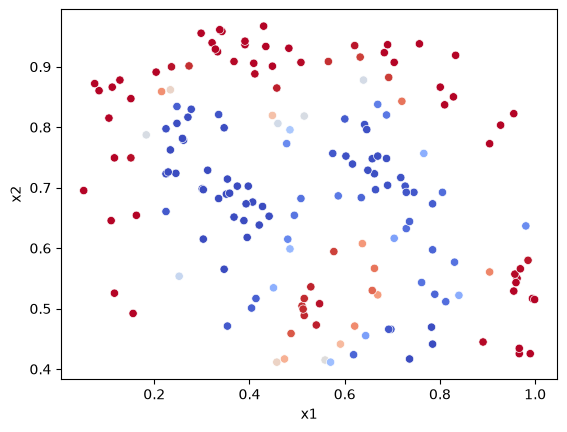

In [230]:
sns.scatterplot(df_eval, x='x1', y='x2', c=df_eval['y_pred'], cmap='coolwarm')

In [231]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures

pipe = Pipeline((
    ('polynomial', PolynomialFeatures()),
    ('classifier', LinearSVC(max_iter=100000))
))

params_svc = {'polynomial__degree': np.arange(2,6),
              'classifier__C': np.logspace(-1,2, 5)}

gs = GridSearchCV(pipe, params_svc, cv=5, scoring='accuracy', verbose=2)
gs.fit(X_train, y_train)

print(gs.best_estimator_)
print(gs.best_params_)
print(gs.best_score_)

final_model = gs.best_estimator_
final_model.fit(X_train, y_train)
final_model.score(X_test, y_test)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
[CV] END ............classifier__C=0.1, polynomial__degree=2; total time=   0.0s
[CV] END ............classifier__C=0.1, polynomial__degree=2; total time=   0.0s
[CV] END ............classifier__C=0.1, polynomial__degree=2; total time=   0.0s
[CV] END ............classifier__C=0.1, polynomial__degree=2; total time=   0.0s
[CV] END ............classifier__C=0.1, polynomial__degree=2; total time=   0.0s
[CV] END ............classifier__C=0.1, polynomial__degree=3; total time=   0.0s
[CV] END ............classifier__C=0.1, polynomial__degree=3; total time=   0.0s
[CV] END ............classifier__C=0.1, polynomial__degree=3; total time=   0.0s
[CV] END ............classifier__C=0.1, polynomial__degree=3; total time=   0.0s
[CV] END ............classifier__C=0.1, polynomial__degree=3; total time=   0.0s
[CV] END ............classifier__C=0.1, polynomial__degree=4; total time=   0.0s
[CV] END ............classifier__C=0.1, polynom

0.838150289017341

In [232]:
pipe = Pipeline((
    ('polynomial', PolynomialFeatures()),
    ('classifier', SVC(max_iter=100000))
))

params_svc = {'polynomial': [PolynomialFeatures(2), PolynomialFeatures(3), None],
            #   'polynomial__degree': np.arange(2,6),
            #   'classifier': [SVC(max_iter=100000)],
              'classifier__C': np.logspace(-1,2, 5),
              'classifier__kernel': ['linear', 'rbf']}

gs = GridSearchCV(pipe, params_svc, cv=5, scoring='accuracy', verbose=2)
gs.fit(X_train, y_train)

print(gs.best_estimator_)
print(gs.best_params_)
print(gs.best_score_)

final_model = gs.best_estimator_
final_model.fit(X_train, y_train)
final_model.score(X_test, y_test)

Fitting 5 folds for each of 30 candidates, totalling 150 fits
[CV] END classifier__C=0.1, classifier__kernel=linear, polynomial=PolynomialFeatures(); total time=   0.0s
[CV] END classifier__C=0.1, classifier__kernel=linear, polynomial=PolynomialFeatures(); total time=   0.0s
[CV] END classifier__C=0.1, classifier__kernel=linear, polynomial=PolynomialFeatures(); total time=   0.0s
[CV] END classifier__C=0.1, classifier__kernel=linear, polynomial=PolynomialFeatures(); total time=   0.0s
[CV] END classifier__C=0.1, classifier__kernel=linear, polynomial=PolynomialFeatures(); total time=   0.0s
[CV] END classifier__C=0.1, classifier__kernel=linear, polynomial=PolynomialFeatures(degree=3); total time=   0.0s
[CV] END classifier__C=0.1, classifier__kernel=linear, polynomial=PolynomialFeatures(degree=3); total time=   0.0s
[CV] END classifier__C=0.1, classifier__kernel=linear, polynomial=PolynomialFeatures(degree=3); total time=   0.0s
[CV] END classifier__C=0.1, classifier__kernel=linear, pol

0.9248554913294798